# SEM fluid-solid · water over an elastic sea floor

`AcousticElasticSEM2D` solves the water and the solid below it on one mesh: the fluid as an
acoustic potential, the solid as an elastic displacement, coupled through the sea floor. One
call gives pressure and particle velocity in the water and on the sea floor (ocean-bottom
nodes). What differs from the other equations is how the model is given:

1. The sea floor as a mesh interface: `interfaces=` and `layered_model`, over a seamount
2. Hydrophones and ocean-bottom nodes: `p`, `vx` and `vz` at every receiver
3. The wavefield: a snapshot of the solid

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.sem import PropSEM
from sweep.sem.equations import AcousticElasticSEM2D
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'

Water over a soft sea floor (`vs = 800 m/s`) with a faster layer from 600 m. The slowest wave
is the shear wave in the sea floor, which sets the resolution: 6 Hz and 40 m elements.

In [2]:
dh, n_order, f0 = 10.0, 4, 6.0
shape = (101, 241)                         # 1 km x 2.4 km
z_layer = 600.0                            # the top of the deeper layer
dt, nt = 0.7e-3, 2800
wavelet = ricker(np.arange(nt) * dt - 1.2 / f0, f=f0).astype(np.float32)

## 1. The sea floor as a mesh interface

The equation decides which elements are fluid from `vs`: an element is fluid if `vs = 0` at
all its nodes and solid if `vs > 0` at all of them, so a grid model whose sea floor crosses an
element is refused. `interfaces=` makes the mesh follow the sea floor, as in
[SEM mesh and time step](../50_sem_mesh_and_time_step/): each interface is its row in every
column, top-down, here the sea floor and the top of the deeper layer. Every element then lies
in one layer, and `solver.layered_model(values)` builds the model on the element nodes, one
value per layer; `vs = 0` makes the top layer water. The sea floor is 240 m deep and rises to
140 m over a seamount.

model on the element nodes: (2800, 5, 5) (n_elements, ngll, ngll)


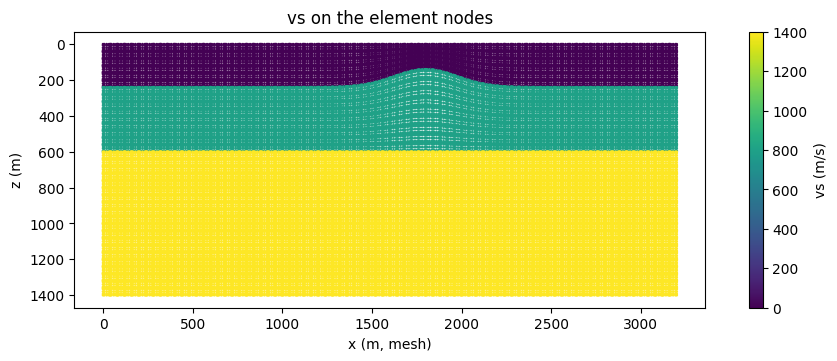

In [3]:
x = np.arange(shape[1]) * dh
seafloor = (240.0 - 100.0 * np.exp(-((x - 1400.0) / 250.0) ** 2)) / dh   # rows, top-down
solver = PropSEM(AcousticElasticSEM2D, shape=shape, dh=dh, dt=dt, n_order=n_order,
                 abcn=40, free_surface=True, f_dominant=f0,
                 interfaces=[seafloor, np.full(shape[1], z_layer / dh)], device=device)
models = [solver.layered_model(v) for v in ([1500.0, 2000.0, 2800.0],     # vp: water, sea floor, deep
                                            [0.0, 800.0, 1400.0],          # vs
                                            [1000.0, 1900.0, 2200.0])]     # rho
print('model on the element nodes:', tuple(models[0].shape), '(n_elements, ngll, ngll)')

mesh = solver.mesh
fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
sc = ax.scatter(mesh.x_e.flatten().cpu(), mesh.z_e.flatten().cpu(), c=models[1].flatten().cpu(),
                s=1, cmap='viridis')
ax.invert_yaxis(); ax.set_aspect('equal')
ax.set_xlabel('x (m, mesh)'); ax.set_ylabel('z (m)'); ax.set_title('vs on the element nodes')
fig.colorbar(sc, ax=ax, label='vs (m/s)')
plt.show()

## 2. Hydrophones and ocean-bottom nodes

A source 20 m below the sea surface; the default `source_type=['chi']` takes the wavelet as the
pressure source. Two receiver lines in one call, hydrophones 40 m deep and ocean-bottom nodes
just below the sea floor. Without a `receiver_type` the class records `['p', 'vx', 'vz']` at
every receiver, each in the medium it sits in; [Receivers · pressure, particle velocity,
rotation, DAS](../47_sem_receivers/) has more on them.

In [4]:
src = np.array([[120, 2]])                                    # x = 1200 m, 20 m deep
rx = np.arange(0, shape[1], 2)
hydrophones = np.stack([rx, np.full_like(rx, 4)], axis=1)
nodes = np.stack([rx, np.ceil(seafloor[rx]) + 1], axis=1)     # 10-20 m below the sea floor
receivers = np.concatenate([hydrophones, nodes])[None]        # (1, 2 * nrec, 2)

with torch.no_grad():
    seis = solver(wavelet, src, receivers, models=models)
print('record', tuple(seis.shape), ' components', solver.receiver_type)
nr = len(rx)
rec_hyd = seis[0, :, :nr].cpu().numpy()                       # (nt, nrec, [p, vx, vz])
rec_obn = seis[0, :, nr:].cpu().numpy()

record (1, 2800, 242, 3)  components ['p', 'vx', 'vz']


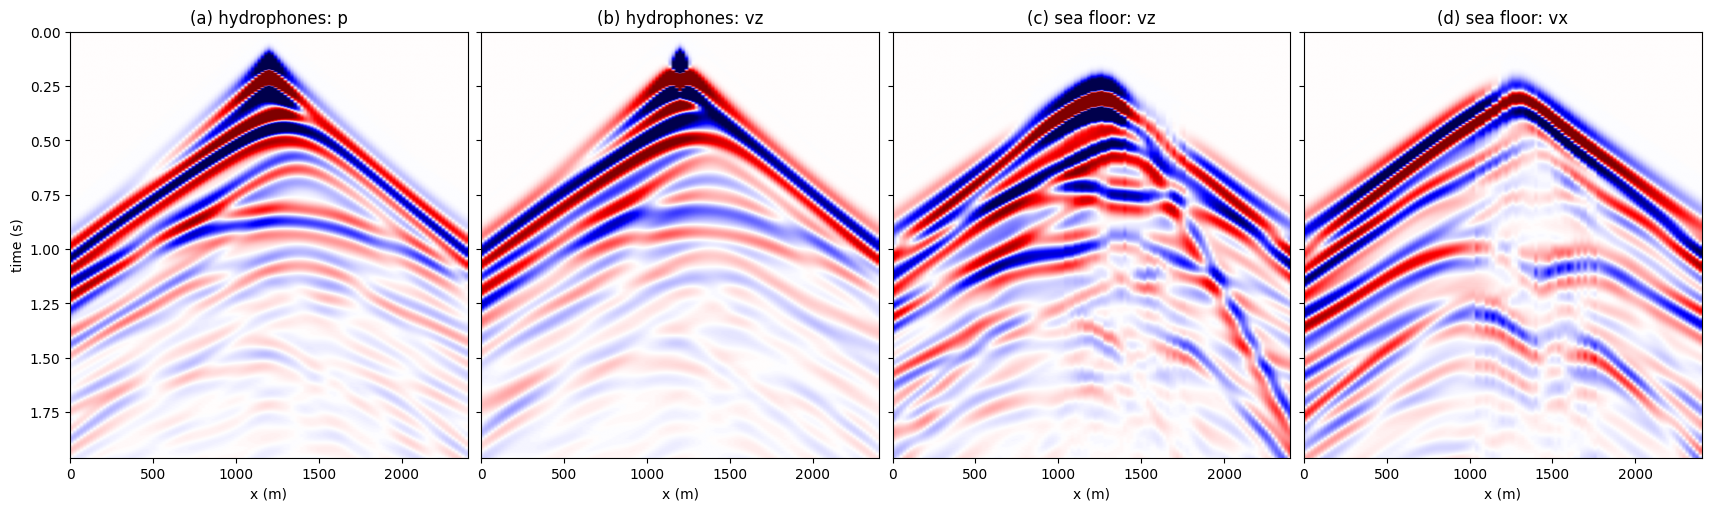

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(17, 5), sharey=True, constrained_layout=True)
for ax, g, title in zip(axes, [rec_hyd[..., 0], rec_hyd[..., 2], rec_obn[..., 2], rec_obn[..., 1]],
                        ['(a) hydrophones: p', '(b) hydrophones: vz', '(c) sea floor: vz',
                         '(d) sea floor: vx']):
    v = np.percentile(np.abs(g), 98)
    ax.imshow(g, cmap='seismic', vmin=-v, vmax=v, aspect='auto',
              extent=[rx[0] * dh, rx[-1] * dh, nt * dt, 0])
    ax.set_title(title); ax.set_xlabel('x (m)')
axes[0].set_ylabel('time (s)')
plt.show()

The hydrophones record the direct wave, the sea-floor reflection and the reverberations in the
water layer, whose period is about `2 x 240 m / 1500 m/s = 0.32 s` away from the seamount and
shorter over it, on `p` and `vz` alike. On the sea floor `vz` holds the same reverberations,
and both components carry slower, steeper events that start at the seamount and run along the
sea floor; the hydrophones above it do not record them.

## 3. The wavefield

Snapshots (eager) hold each domain's own field: the potential `chi` in the water, the
displacement `u_x`, `u_z` in the solid. The vertical displacement at 1.2 s, with the water
blanked, where it is not defined:

sweep: torch.compile is compiling the AcousticElasticSEM2D step for a 101x241 grid; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


snapshot fields ['chi', 'u_x', 'u_z'] (1, 3, 1, 1, 141, 321)


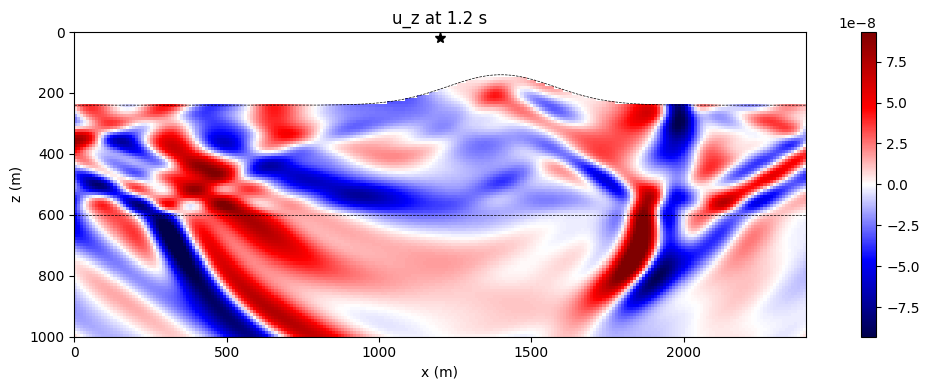

In [6]:
solver_e = PropSEM(AcousticElasticSEM2D, shape=shape, dh=dh, dt=dt, n_order=n_order,
                   abcn=40, free_surface=True, f_dominant=f0,
                   interfaces=[seafloor, np.full(shape[1], z_layer / dh)], impl='eager',
                   device=device)
step = int(round(1.2 / dt))
with torch.no_grad():
    _, snaps = solver_e(wavelet, src, receivers, models=models,
                        return_wavefield=True, snapshot_times=[step])
print('snapshot fields', solver_e.snapshot_fields, tuple(snaps.shape))
uz = snaps[0, solver_e.snapshot_fields.index('u_z'), 0, 0].numpy()
uz = uz[:shape[0], 40:40 + shape[1]]                          # crop the C-PML
uz[np.arange(shape[0])[:, None] < seafloor[None, :]] = np.nan  # the water
v = np.nanpercentile(np.abs(uz[uz != 0]), 99)
plt.figure(figsize=(12, 4))
plt.imshow(uz, cmap='seismic', vmin=-v, vmax=v,
           extent=[0, (shape[1] - 1) * dh, (shape[0] - 1) * dh, 0])
plt.plot(x, seafloor * dh, 'k--', lw=0.5); plt.axhline(z_layer, color='k', lw=0.5, ls='--')
plt.plot(src[0, 0] * dh, src[0, 1] * dh, 'k*', ms=8)
plt.xlabel('x (m)'); plt.ylabel('z (m)'); plt.title('u_z at 1.2 s')
plt.colorbar(); plt.tight_layout(); plt.show()

## Summary

- `AcousticElasticSEM2D` takes `[vp, vs, rho]`; `vs = 0` marks the fluid, element by element.
- `interfaces=` makes the mesh follow the sea floor and the interfaces below it;
  `layered_model(values)` gives the model on the element nodes, one value per layer.
- Without `receiver_type` the class records `['p', 'vx', 'vz']` at every receiver, in the water
  and in the rock; it runs on `impl='c'`, with shot batching and boundary saving.

Next: [SEM in 3-D · acoustic, elastic, topography and Biot](../56_sem_3d/).

---

<p><strong>Download this notebook</strong> &mdash; <a href="55_sem_fluid_solid.ipynb" download><code>55_sem_fluid_solid.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/55_sem_fluid_solid.ipynb">view on GitHub</a></p>